> **AI use declaration.** Parts of the code and text in this notebook were generated with the help of an AI assistant (Claude, by Anthropic), as allowed for this assignment. I (Kularathna G.G.A.S., 224110P) ran every cell, checked the outputs and the numbers quoted in the text, and made the final modelling decisions.


# 09 - Hybridization: Random Forest + ARIMA

## 1. Objective

This notebook covers the lecture's hands-on point **"Try hybridization: RF + ARIMA for time-series"**. Dengue cases are a weekly time series, so RF + ARIMA is the hybrid that fits this data (RF + ANN is meant for plain tabular regression). It is an **extension** to the main bagging vs boosting vs stacking comparison in notebook 08 and does not replace it.

The idea of a **hybrid** is to combine two kinds of model so that each covers what the other misses (Zhang, 2003, combined ARIMA with a neural network in this way):

- The **Random Forest** treats every district-week as a separate row. It does not know that its own errors in consecutive weeks may be related.
- An **ARIMA** model is a classic time-series model. It predicts the next value of a series from its own recent values.

**Hybrid used here (residual correction):**

1. The Random Forest predicts next week's cases.
2. Its **error** (residual = actual - predicted) is tracked week by week for each reporting area.
3. A small ARIMA model predicts **next week's Random Forest error** from the recent errors.
4. Hybrid prediction = Random Forest prediction + predicted error (clipped at 0).

## 2. Is this scientifically appropriate for this data?

**Arguments for:**
- The data is a weekly **time series** per reporting area. Tree models only see the time structure through the lag features; ARIMA models it directly.
- Notebooks 05-08 show that the models follow the actual curve **about one week late**. During a rise they underestimate for several weeks in a row, so their errors are likely to be **autocorrelated**. A residual model can use exactly that kind of pattern.

**Arguments against / risks:**
- ARIMA assumes the residual series is roughly **linear, stationary and with constant variance**. Dengue errors are small in normal weeks and very large in outbreaks (changing variance), and they change sign suddenly at the top of an outbreak.
- An AR model **continues the most recent error**. Right after a peak, the last error was an underestimate, so the correction pushes the prediction **up** just when cases start to fall - where the largest errors already are.
- Each reporting area has only 52 out-of-sample validation errors (2023) to estimate the ARIMA parameters.

So the hybrid is reasonable to **test**, but there is no guarantee it helps. It is evaluated exactly like the other models.

## 3. How leakage is avoided

1. **Out-of-sample errors only.** ARIMA must not learn from the Random Forest's **training** errors: a Random Forest fits its training data closely, so those errors are much smaller than real forecast errors and would make the hybrid look too good.
   - The ARIMA parameters are estimated on **2023 validation errors** from the Random Forest trained on 2007-2022 (the same model as notebook 05), i.e. weeks that model had not seen.
   - On the test years, the errors of the **final Random Forest** from notebook 05 are used. Those weeks were never used for training it.
2. **Only past errors are used.** A row's error (target week = next week) is only known **one week later**. When predicting the row of week *t*, ARIMA only has the errors of rows up to week *t-1*. The test weeks are processed one at a time in date order.
3. **No refitting and no tuning on the test set.** The ARIMA order is fixed in advance as **ARIMA(1,0,0)** ("next error = coefficient x last error"), the simplest model that uses the last error. Its coefficient is estimated on 2023 only. During the test years new errors are added to the history (`append`) but the coefficient is **not** re-estimated.
4. **Same test rows** as notebook 08 (3,508), same leakage check.

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from statsmodels.tsa.arima.model import ARIMA

TRAIN_PATH = Path("../dataset/processed/train.csv")
TEST_PATH = Path("../dataset/processed/test.csv")
CONFIG_PATH = Path("../models/05_random_forest_results.json")
RF_MODEL_PATH = Path("../models/05_final_random_forest_model.joblib")
RESULTS_08_PATH = Path("../models/08_final_test_results.json")
RESULTS_PATH = Path("../models/09_hybrid_rf_arima_results.json")

config = json.loads(CONFIG_PATH.read_text())
results_08 = json.loads(RESULTS_08_PATH.read_text())
FEATURES = config["features"]
TARGET = config["target"]
RANDOM_STATE = config["random_state"]
VALIDATION_YEAR = config["validation_year"]
RF_PARAMS = {k: v for k, v in results_08["random_forest_params"].items() if k != "random_state"}

ARIMA_ORDER = (1, 0, 0)  # fixed in advance: next error = coefficient x last error

MODELS = ["Persistence", "Random Forest", "RF + ARIMA"]
COLORS = {"Persistence": "#898781", "Random Forest": "#2a78d6", "RF + ARIMA": "#eb6834"}
INK, GRID = "#0b0b0b", "#e4e3df"
print("Random Forest settings:", RF_PARAMS, "| ARIMA order:", ARIMA_ORDER)

Random Forest settings: {'n_estimators': 200, 'min_samples_leaf': 10, 'max_features': 0.5} | ARIMA order: (1, 0, 0)


## 4. Load the data (same as notebooks 05-08)

In [2]:
train = pd.read_csv(TRAIN_PATH, parse_dates=["start_date", "target_date"])
test = pd.read_csv(TEST_PATH, parse_dates=["start_date", "target_date"])
train = train[~(train["is_imputed"] | train["target_imputed"])].reset_index(drop=True)
test = test[~(test["is_imputed"] | test["target_imputed"])].reset_index(drop=True)

assert train["target_date"].max() < test["target_date"].min()
assert len(test) == results_08["test_rows"]  # same 3,508 test rows as notebook 08
print("training rows:", len(train), "| test rows:", len(test))

training rows: 21684 | test rows: 3508


## 5. Random Forest errors

**5.1 Validation errors (2023)** - from a Random Forest trained on 2007-2022 only (exactly as in notebook 05), so 2023 is unseen for it.

In [3]:
target_year = train["target_date"].dt.year
fit_part = train[target_year < VALIDATION_YEAR]
valid = train[target_year == VALIDATION_YEAR].copy()

rf_valid = RandomForestRegressor(**RF_PARAMS, random_state=RANDOM_STATE, n_jobs=-1)
rf_valid.fit(fit_part[FEATURES], fit_part[TARGET])
rf_valid.set_params(n_jobs=1)

valid["rf_pred"] = rf_valid.predict(valid[FEATURES])
valid["residual"] = valid[TARGET] - valid["rf_pred"]

valid_mae = mean_absolute_error(valid[TARGET], valid["rf_pred"])
print(f"2023 validation MAE: {valid_mae:.3f} (notebook 05: {config['validation_scores']['Random Forest']['MAE']})")
assert abs(valid_mae - config["validation_scores"]["Random Forest"]["MAE"]) < 0.0005

2023 validation MAE: 17.853 (notebook 05: 17.853)


**5.2 Test errors (2024-2026)** - from the final Random Forest saved in notebook 05 (trained on 2007-2023).

In [4]:
final_rf = joblib.load(RF_MODEL_PATH)
test["rf_pred"] = final_rf.predict(test[FEATURES])
test["residual"] = test[TARGET] - test["rf_pred"]

# must be the same Random Forest score as notebook 08
assert round(mean_absolute_error(test[TARGET], test["rf_pred"]), 3) == results_08["test_scores"]["Random Forest"]["MAE"]

**5.3 Is there anything for ARIMA to learn?**

If the errors of consecutive weeks are unrelated, ARIMA cannot help. The **lag-1 autocorrelation** measures how similar each week's error is to the previous week's error (0 = unrelated, 1 = identical). It is computed per reporting area on the 2023 validation errors only.

In [5]:
lag1 = (valid.sort_values("start_date")
        .groupby("district")["residual"]
        .apply(lambda errors: errors.autocorr(lag=1)))
print("lag-1 autocorrelation of 2023 Random Forest errors, 26 reporting areas:")
lag1.describe().round(2)

lag-1 autocorrelation of 2023 Random Forest errors, 26 reporting areas:


count    26.00
mean      0.06
std       0.27
min      -0.32
25%      -0.14
50%       0.01
75%       0.19
max       0.68
Name: residual, dtype: float64

**What this shows:** the median lag-1 autocorrelation is about **0** (0.01), and in almost half of the reporting areas it is negative. Only a few areas have a clear positive value (up to 0.68). So, against the expectation in section 2, the Random Forest's errors in one week say **very little** about its error in the next week. This already suggests that a residual ARIMA has little to work with. The experiment is still run as planned, to measure the effect rather than assume it.

## 6. Fit ARIMA on 2023 and walk forward through the test weeks

For each reporting area:
1. Fit ARIMA(1,0,0) on its 52 validation errors of 2023.
2. Go through the test weeks in date order. For each week: **first** predict that row's error from the errors known so far, **then** add the row's real error to the history (it becomes known one week later, before the next row is predicted).
3. Weeks whose row was removed by the leakage check get a missing value (`NaN`) in the history; ARIMA handles missing values.

The coefficient stays the one estimated on 2023 (`append` does not refit).

In [6]:
correction = pd.Series(np.nan, index=test.index)
ar_coefficients = {}

for district in sorted(test["district"].unique()):
    history = valid[valid["district"] == district].sort_values("start_date")
    district_test = test[test["district"] == district].sort_values("start_date")

    # weekly timeline of the test period; the first test week follows the last validation week
    weeks = pd.date_range(district_test["start_date"].min(), district_test["start_date"].max(), freq="7D")
    assert history["start_date"].max() + pd.Timedelta(days=7) == weeks[0]
    row_of_week = dict(zip(district_test["start_date"], district_test.index))

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # small-sample convergence messages from statsmodels
        arima = ARIMA(history["residual"].to_numpy(), order=ARIMA_ORDER, trend="n").fit()
        ar_coefficients[district] = arima.params[0]

        for week in weeks:
            if week in row_of_week:
                row = row_of_week[week]
                correction[row] = arima.forecast(1)[0]                 # uses errors up to the previous week only
                known_error = test.loc[row, "residual"]
            else:
                known_error = np.nan                                     # row removed by the leakage check
            arima = arima.append([known_error])                          # becomes known one week later; no refit

assert correction.notna().all()
test["arima_correction"] = correction
test["hybrid_pred"] = np.clip(test["rf_pred"] + test["arima_correction"], 0, None)

print("AR(1) coefficient per reporting area (estimated on 2023 only):")
pd.Series(ar_coefficients).describe().round(2)

AR(1) coefficient per reporting area (estimated on 2023 only):


count    26.00
mean      0.07
std       0.30
min      -0.29
25%      -0.13
50%       0.01
75%       0.20
max       0.94
dtype: float64

**Check that no future information was used:** the correction for the first test week of every reporting area must equal what the 2023-only model forecasts, i.e. it cannot depend on any test value.

In [7]:
for district in ["Colombo", "Mullaitivu"]:
    history = valid[valid["district"] == district].sort_values("start_date")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        first_forecast = ARIMA(history["residual"].to_numpy(), order=ARIMA_ORDER, trend="n").fit().forecast(1)[0]
    first_row = test[test["district"] == district].sort_values("start_date").index[0]
    assert np.isclose(test.loc[first_row, "arima_correction"], first_forecast)
print("first test-week corrections depend only on 2023 errors")

first test-week corrections depend only on 2023 errors


## 7. Results on the test set (2024-2026)

Same 3,508 rows as notebook 08. Negative change = smaller error than persistence.

In [8]:
y_test = test[TARGET].to_numpy()
predictions = {
    "Persistence": test["current_week_cases"].to_numpy(dtype=float),
    "Random Forest": test["rf_pred"].to_numpy(),
    "RF + ARIMA": test["hybrid_pred"].to_numpy(),
}


def score_table(rows):
    table = pd.DataFrame({name: {"MAE": mean_absolute_error(y_test[rows], p[rows]),
                                 "RMSE": root_mean_squared_error(y_test[rows], p[rows])}
                          for name, p in predictions.items()}).T
    table["MAE vs persistence (%)"] = 100 * (table["MAE"] / table.loc["Persistence", "MAE"] - 1)
    table["RMSE vs persistence (%)"] = 100 * (table["RMSE"] / table.loc["Persistence", "RMSE"] - 1)
    return table


hybrid_results = score_table(np.ones(len(test), dtype=bool))
hybrid_results.round(2)

,MAE,RMSE,MAE vs persistence (%),RMSE vs persistence (%)
Persistence,12.63,29.93,0.00,0.00
Random Forest,12.48,33.36,-1.17,11.47
RF + ARIMA,12.80,34.16,1.32,14.14


In [9]:
test_year = test["target_date"].dt.year.to_numpy()
current = test["current_week_cases"].to_numpy()
groups = {f"{year}": test_year == year for year in sorted(np.unique(test_year))}
groups["current week > 500"] = current > 500
groups["current week <= 500"] = current <= 500

group_rows = []
for label, rows in groups.items():
    row = {"rows": int(rows.sum())}
    for name, p in predictions.items():
        row[f"{name} MAE"] = mean_absolute_error(y_test[rows], p[rows])
    group_rows.append(pd.Series(row, name=label))
by_group = pd.DataFrame(group_rows)
by_group.round(2)

,rows,Persistence MAE,Random Forest MAE,RF + ARIMA MAE
2024,1352.0,10.45,9.56,9.76
2025,1352.0,8.68,8.19,8.38
2026,804.0,22.93,24.62,25.32
current week > 500,37.0,169.08,188.49,202.72
current week <= 500,3471.0,10.96,10.61,10.77


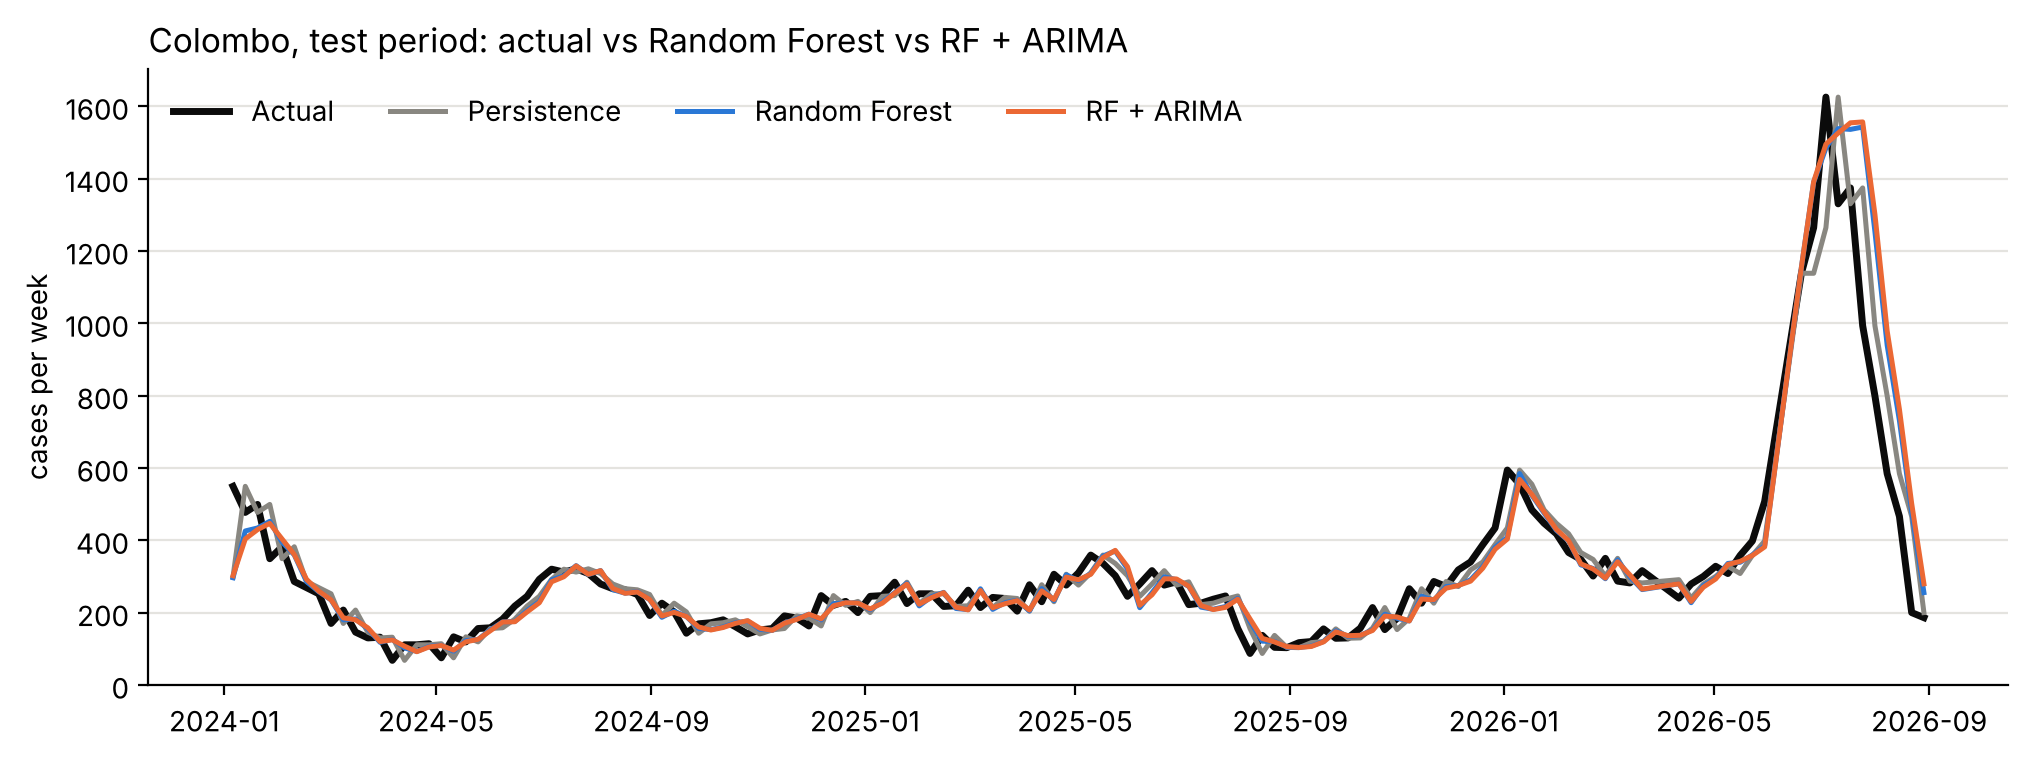

In [10]:
rows = (test["district"] == "Colombo").to_numpy()
dates = test.loc[rows, "target_date"]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(dates, y_test[rows], color=INK, linewidth=2.5, label="Actual")
for name in MODELS:
    ax.plot(dates, predictions[name][rows], color=COLORS[name], linewidth=1.8, label=name)
ax.set_title("Colombo, test period: actual vs Random Forest vs RF + ARIMA", loc="left")
ax.set_ylabel("cases per week")
ax.set_ylim(bottom=0)
ax.grid(axis="y", color=GRID)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, ncol=4)
plt.show()

**What the results show**

- **The hybrid is worse than the Random Forest alone**: MAE 12.80 vs 12.48 (about 2.6% worse) and RMSE 34.16 vs 33.36. It is also worse than persistence (MAE +1.3%).
- It is worse **in every test year** (2024: 9.76 vs 9.56, 2025: 8.38 vs 8.19, 2026: 25.32 vs 24.62) and both in normal weeks (10.77 vs 10.61) and in outbreak weeks above 500 cases (202.7 vs 188.5).
- **Why:**
  1. The Random Forest errors are hardly autocorrelated (section 5.3), so the AR(1) corrections are mostly noise added to a good prediction.
  2. Where the errors *are* related, the relation breaks at turning points: after an outbreak peak, the last error was an underestimate, so ARIMA pushes the next prediction up just as cases fall.
  3. The coefficients are estimated from only 52 errors per area, from one year (2023) with a different model (trained to 2022) than the one used on the test years.

In [11]:
results = {
    "created_by": "notebooks analysis/09_hybrid_rf_arima.ipynb",
    "note": "Hybridization extension (lecture hands-on point). Not part of the main bagging vs boosting vs stacking comparison.",
    "arima_order": list(ARIMA_ORDER),
    "arima_fitted_on": "2023 out-of-sample Random Forest errors (Random Forest trained on 2007-2022)",
    "test_rows": int(len(test)),
    "test_scores": {k: {c: float(v) for c, v in row.items()} for k, row in hybrid_results.round(3).to_dict(orient="index").items()},
    "mae_by_group": {k: {c: float(v) for c, v in row.items()} for k, row in by_group.round(3).to_dict(orient="index").items()},
    "lag1_autocorrelation_2023_median": float(lag1.median()),
}
RESULTS_PATH.write_text(json.dumps(results, indent=2))
print("saved", RESULTS_PATH)

saved ../models/09_hybrid_rf_arima_results.json


## 8. Summary

| Model | Test MAE | Test RMSE | MAE vs persistence | RMSE vs persistence |
|---|---|---|---|---|
| Persistence | 12.63 | 29.93 | - | - |
| Random Forest | 12.48 | 33.36 | -1.2% | +11.5% |
| RF + ARIMA(1,0,0) residual hybrid | 12.80 | 34.16 | +1.3% | +14.1% |

**Conclusion (negative result):** a leakage-free Random Forest + ARIMA residual hybrid **does not improve** the forecasts on this data. The Random Forest's errors are close to unpredictable from week to week, so the time-series correction mainly adds noise. The main project result (notebook 08, bagging vs boosting vs stacking) is unchanged; the dashboard reports this hybrid only as an extension.

**What was done to keep it fair:** ARIMA was fitted only on out-of-sample 2023 errors, its order was fixed in advance, it was never refitted on test weeks, and each test week's correction used only errors that were already known at that time. An in-sample version (ARIMA on the Random Forest's own training errors) would have been easy to build but would give over-optimistic results, because a Random Forest's training errors are much smaller than its real forecast errors.

**Ideas that were not tried** (they would need a new, untouched test period to be evaluated fairly):
- A standalone seasonal ARIMA/SARIMA per area, refitted every week on log cases, as an extra classical baseline.
- The "classical" order of a hybrid (Zhang, 2003): ARIMA first, then a tree model on ARIMA's errors.
- Adding weather data (rainfall, temperature), which is more likely to signal turning points than the past errors are.

**Reference:** Zhang, G. P. (2003). Time series forecasting using a hybrid ARIMA and neural network model. *Neurocomputing*, 50, 159-175.